In [6]:
# À décommenter si xlrd, le lecteur des fichiers .xls, n’est pas installé.
# %pip install xlrd


In [3]:
# Pandas prépare les données ; Matplotlib construit les graphiques.
import pandas as pd
import matplotlib.pyplot as plt

# Charger uniquement la feuille Orders du classeur Superstore.
df = pd.read_excel(
    "/workspace/data/sample_-_superstore.xls",
    sheet_name="Orders"
)

# Examiner les colonnes, leurs types et le nombre de valeurs renseignées.
df.info()

# Utiliser le nom orders pour les calculs qui suivent.
orders = df


<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [2]:
# shape donne le nombre de lignes et de colonnes du tableau.
print(orders.shape)

# Afficher les noms des colonnes pour vérifier les champs disponibles.
print(orders.columns.tolist())


(10194, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [4]:
# len compte les lignes de commande, pas les commandes distinctes.
print('Lignes :', len(orders))

# nunique compte chaque identifiant de commande une seule fois.
print('Commandes distinctes :', orders['Order ID'].nunique())

# Compter les catégories différentes, même si leurs noms se répètent.
print('Catégories :', orders['Category'].nunique())


Lignes : 10194
Commandes distinctes : 5111
Catégories : 3


In [6]:
# Pour afficher les identifiants distincts plutôt que leur nombre :
# orders['Order ID'].unique()


In [7]:
# Exercice 01 — compter les sous-catégories différentes.
# nunique ignore les répétitions de noms dans les lignes du fichier.
print( f" nombre de sous catégories {orders["Sub-Category"].nunique()}")


 nombre de sous catégories 17


In [8]:
# Regrouper les lignes de commande appartenant à la même catégorie.
# agg applique deux comptages à la colonne Order ID de chaque groupe.
par_categorie = orders.groupby("Category")["Order ID"].agg(
    lignes="size",       # Compter toutes les lignes du groupe.
    commandes="nunique"  # Compter les identifiants de commande différents.
)

# Afficher le tableau : une ligne par catégorie et deux comptages.
par_categorie


,lignes,commandes
Category,,
Furniture,2201,1819
Office Supplies,6128,3812
Technology,1865,1560


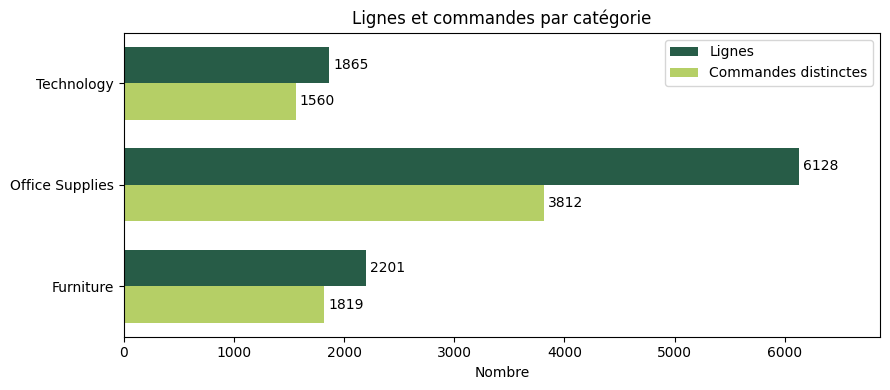

In [9]:
# Créer une figure de 9 × 4 pouces et sa zone de tracé ax.
fig, ax = plt.subplots(figsize=(9, 4))

# Attribuer une position verticale à chaque catégorie : 0, 1, 2…
y = range(len(par_categorie))

# Tracer le nombre de lignes en vert, au-dessus du centre de chaque paire.
# Le décalage +0.18 et la hauteur 0.36 séparent les deux séries.
b1 = ax.barh(
    [i + 0.18 for i in y],
    par_categorie["lignes"],
    height=0.36,
    label="Lignes",
    color="#275c47"
)

# Tracer les commandes distinctes en lime, en dessous du centre.
b2 = ax.barh(
    [i - 0.18 for i in y],
    par_categorie["commandes"],
    height=0.36,
    label="Commandes distinctes",
    color="#b5cf66"
)

# Inscrire les comptages au bout des barres, avec un espace de 3 points.
ax.bar_label(b1, padding=3)
ax.bar_label(b2, padding=3)

# Remplacer les positions numériques par les noms des catégories.
ax.set_yticks(list(y), par_categorie.index)

# Préciser la comparaison et l’unité de l’axe horizontal.
ax.set(
    title="Lignes et commandes par catégorie",
    xlabel="Nombre"
)

# Associer les couleurs aux deux comptages grâce aux labels des séries.
ax.legend()

# Laisser 12 % de marge pour que les valeurs restent visibles.
ax.margins(x=0.12)

# Ajuster les espacements, puis afficher la figure dans le notebook.
plt.tight_layout()
plt.show()


In [10]:
# Exercice 02 — appliquer les deux comptages aux régions.
# Une même commande peut occuper plusieurs lignes dans sa région.
par_region = orders.groupby("Region")["Order ID"].agg(
    lignes="size",       # Toutes les lignes de commande de la région.
    commandes="nunique"  # Chaque commande de la région comptée une fois.
)

# Afficher les comptages avant de calculer leur écart.
print(par_region)


         lignes  commandes
Region                    
Central    2335       1179
East       2986       1475
South      1620        822
West       3253       1635


### Exercice 02

Comparer les écarts par région

Dans quelle région l’écart entre lignes et commandes distinctes est-il le plus grand ?

*À rendre : La région, les deux comptages, l’écart et une phrase qui interprète cet écart.*

In [14]:
# Préparer un tableau contenant les deux comptages par région.
par_region = orders.groupby("Region")["Order ID"].agg(
    lignes="size",       # Nombre de lignes dans chaque groupe.
    commandes="nunique"  # Nombre d’identifiants différents dans ce groupe.
)

# Le résultat est un DataFrame dont l’index contient les régions.
par_region


,lignes,commandes
Region,,
Central,2335,1179
East,2986,1475
South,1620,822
West,3253,1635


In [17]:
# Mesurer les lignes au-delà d’une ligne par commande dans chaque région.
# Le nombre de lignes est au moins égal au nombre de commandes :
# abs() conserve ici la même valeur, positive ou nulle.
par_region["ecart"] = abs( par_region["lignes"] - par_region["commandes"] )


In [18]:
# Vérifier les deux comptages et la nouvelle colonne ecart.
par_region


,lignes,commandes,ecart
Region,,,
Central,2335,1179,1156
East,2986,1475,1511
South,1620,822,798
West,3253,1635,1618


In [21]:
# idxmax renvoie le nom de la région, c’est-à-dire l’index de l’écart maximal.
region = par_region["ecart"].idxmax()
region


'West'

In [22]:
# loc sélectionne la ligne portant ce nom de région.
# On récupère ses comptages et son écart pour rédiger la conclusion.
resultat = par_region.loc[region]
resultat


lignes       3253
commandes    1635
ecart        1618
Name: West, dtype: int64

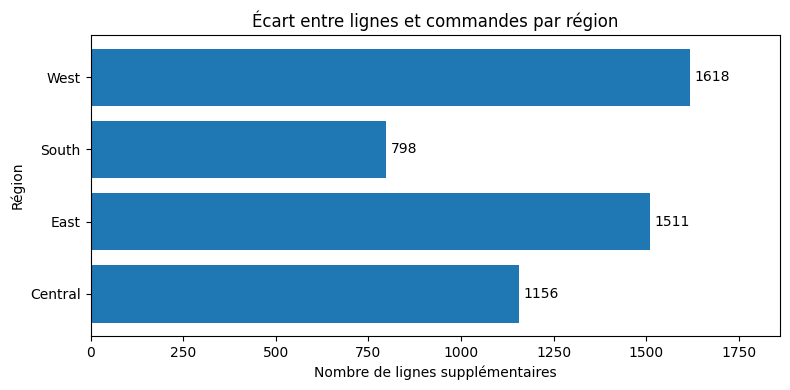

In [23]:
# Comparer les écarts régionaux avec des barres horizontales.
fig, ax = plt.subplots(figsize=(8, 4))

# L’index fournit les régions ; la colonne ecart fournit les longueurs.
barres = ax.barh(par_region.index, par_region["ecart"])
ax.bar_label(barres, padding=3)

# Nommer la mesure pour éviter de la confondre avec le nombre de commandes.
ax.set(
    title="Écart entre lignes et commandes par région",
    xlabel="Nombre de lignes supplémentaires",
    ylabel="Région"
)

# Réserver de la place aux valeurs et aux libellés avant l’affichage.
ax.margins(x=0.15)
plt.tight_layout()
plt.show()


In [24]:
# Formuler une conclusion avec la région et l’écart calculés.
# Cet écart est un nombre total de lignes supplémentaires ;
# il ne mesure ni les quantités vendues ni une moyenne par commande.
print(f"\nLa région {region} présente le plus grand écart "
    f"({resultat['ecart']} lignes supplémentaires). "
    "Cela traduit la présence de commandes contenant plusieurs "
    "lignes de produits, sans nécessairement indiquer "
    "un plus grand nombre de produits par commande."
)



La région West présente le plus grand écart (1618 lignes supplémentaires). Cela traduit la présence de commandes contenant plusieurs lignes de produits, sans nécessairement indiquer un plus grand nombre de produits par commande.


In [25]:
# Extraire l’année de chaque date pour disposer d’une colonne de regroupement.
orders["annee"] = orders["Order Date"].dt.year

# Pour examiner les premières lignes après cet ajout :
# orders.head(2)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,annee
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023


In [27]:
# Compter les commandes distinctes séparément dans chaque année.
# Le résultat est une Series : années en index, comptages en valeurs.
commandes_annee = orders.groupby("annee")["Order ID"].nunique()
commandes_annee


annee
2023     995
2024    1053
2025    1340
2026    1723
Name: Order ID, dtype: int64

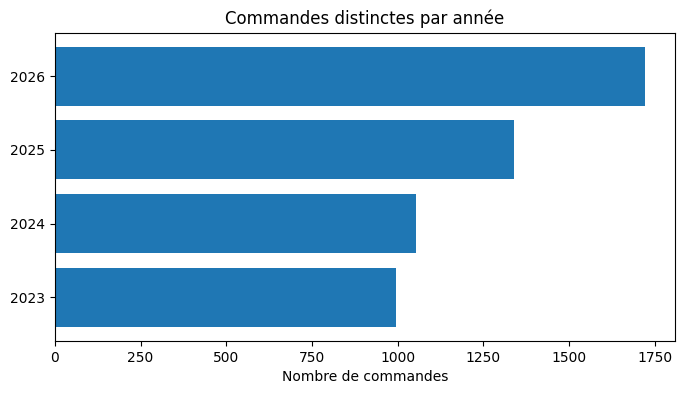

In [28]:
# Représenter le nombre de commandes de chaque année.
fig, ax = plt.subplots(figsize=(8,4))

# Convertir les années en texte pour les utiliser comme catégories de l’axe.
ax.barh(commandes_annee.index.astype(str), commandes_annee.values)
ax.set(title='Commandes distinctes par année', xlabel='Nombre de commandes')
plt.show()


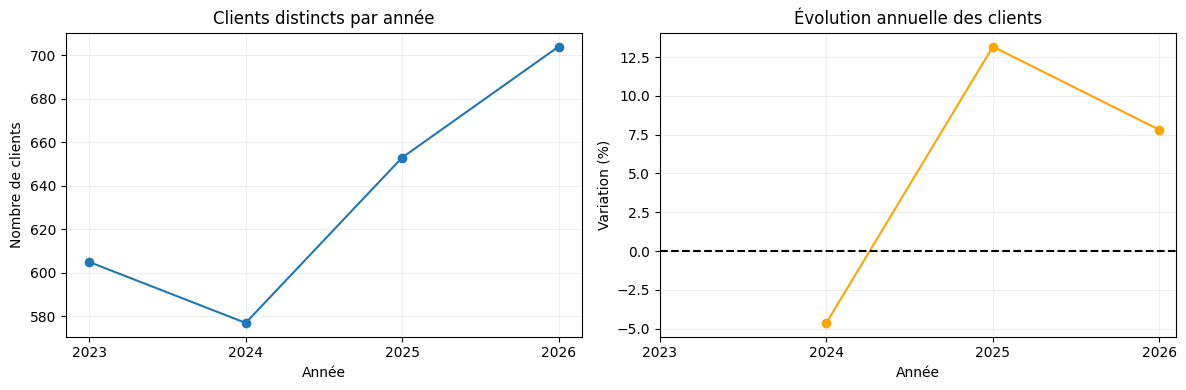

In [30]:
import matplotlib.pyplot as plt

# Compter les clients différents chaque année, sans compter plusieurs fois
# un client qui a passé plusieurs commandes dans la même année.
clients = orders.groupby(orders["Order Date"].dt.year)["Customer ID"].nunique()

# Comparer chaque comptage à celui de l’année précédente, puis passer en %.
# La première année n’a pas de taux calculable faute d’année précédente.
taux = clients.pct_change() * 100

# Créer deux zones de tracé dans une même figure : ax[0] et ax[1].
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# À gauche, montrer le niveau du nombre de clients.
ax[0].plot(clients.index, clients.values, marker="o")
ax[0].set(
    title="Clients distincts par année",
    xlabel="Année",
    ylabel="Nombre de clients"
)
ax[0].set_xticks(clients.index)
ax[0].grid(alpha=0.2)

# À droite, montrer la variation relative, dans une unité différente.
ax[1].plot(taux.index, taux.values, marker="o", color="orange")
ax[1].set(
    title="Évolution annuelle des clients",
    xlabel="Année",
    ylabel="Variation (%)"
)
ax[1].set_xticks(clients.index)

# La ligne zéro sépare les années de hausse et de baisse.
ax[1].axhline(0, color="black", linestyle="--")
ax[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()
